# Approaching Quality Control on MERFISH

In [1]:
%load_ext watermark
%watermark -v -p matplotlib,numpy,pandas,scanpy,seaborn,squidpy

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

matplotlib: 3.11.2
numpy     : 2.4.6
pandas    : 3.1.0
scanpy    : 1.12.4
seaborn   : 0.13.2
squidpy   : 1.8.3



This tutorial uses data from Allen Institute (Zeng, Hongkui, 2025), available in the [Brain Image Library](https://api.brainimagelibrary.org/web/view?bildid=ace-low-zip). It focuses primarily on background noise, but the same approach can be extended to other parameters, such as `total_counts`, `n_genes_by_counts`, and others.

**Note:** This approach can also be applied to other spatial technologies, although the relevant parameters may differ.

## 1. What is background noise, and why do we model it?

Spatial transcriptomics measures molecular signals in their spatial context. However, not every detected signal corresponds to a true target transcript, and not every true transcript is detected. The observed data therefore reflect both the underlying biological signal and technical properties of the measurement process.

In this context, *background noise* refers to signal arising from technical processes that can obscure, distort, or be mistaken for the biological signal of interest. Depending on the platform, these processes may include nonspecific probe binding, optical background, barcode decoding errors, spurious detections, and other assay-specific sources of error.

Background noise matters because it can affect downstream biological interpretation. It may inflate apparent gene expression, obscure low-abundance transcripts, distort estimates of cell-type composition, and influence spatial patterns or cell-level clustering.

Rather than assuming that all observed signal is biological, we can use appropriate controls and diagnostic measurements to characterize technical background and assess its potential impact.

**The objective is not simply to remove as much signal as possible. It is to understand which components of the observed data may be technical, quantify uncertainty where possible, and make defensible decisions about filtering, correction, and downstream analysis.**

## 2. How do we approach background noise in MERFISH and Xenium?

MERFISH and Xenium are both imaging-based spatial transcriptomics technologies that use probes to detect RNA targets within tissue. Both can produce spatially resolved transcript detections, but their probe designs, imaging workflows, decoding procedures, and quality-control measurements differ.

Consequently, background assessment should follow the measurement process of each platform rather than applying one universal threshold.

### MERFISH

MERFISH uses combinatorial fluorescent barcodes and sequential imaging to identify RNA molecules. Blank codewords can serve as negative controls: detections assigned to these codes provide an empirical indicator of background and decoding-related errors.

Useful diagnostic measurements include:

- Blank-codeword detection counts per cell.
- Blank detections as a fraction of all detected counts.
- The spatial distribution of blank detections.
- Relationships between blank signal, total transcript counts, cell size, segmentation, and tissue morphology.

Blank-codeword measurements are informative, but they do not capture every source of technical error. In particular, they should not be interpreted as a direct measurement of all false-positive target-gene detections.

### Xenium

Xenium is also an imaging-based platform, but its assay chemistry, probe design, decoding, and quality-control outputs differ from MERFISH. Background assessment should therefore use the controls and diagnostic information available in the specific Xenium assay and processing output.

Depending on the dataset and software version, useful information may include negative-control probe measurements, transcript-level quality information, cell-level counts, segmentation metrics, and spatial distributions of detected transcripts. These measurements should be verified against the actual Xenium output rather than assumed to be interchangeable with MERFISH metrics.

For both platforms, the central questions are similar:

1. **What technical processes can generate misleading signal?**
2. **Which controls or measurements can help characterize that signal?**
3. **Which cells, transcripts, or regions show evidence of reduced reliability?**
4. **Should the observations be retained, filtered, or corrected—and how can we evaluate the consequences?**

The shared framework is the same, but the controls, metrics, and assumptions must remain platform-specific.

## 3. From measurement to decision

In this notebook, we begin with blank-codeword measurements in MERFISH to characterize one observable component of background signal. We examine its distribution across cells and tissue coordinates, then assess how it relates to other quality-control metrics.

A cell with unusually high blank signal is a candidate for further investigation, not automatically a low-quality cell. Decisions about filtering or correction require additional evidence and should be evaluated for their effects on downstream biological conclusions.

The same reasoning can be extended to Xenium using its corresponding negative controls and quality metrics, while accounting for differences in how the two platforms measure and report technical signal.

In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import seaborn as sns

import matplotlib.pyplot as plt

c:\Users\user\OneDrive\Desktop\GitHub\mini-spatial-series\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
adata = sc.read_h5ad("D:/BioWorkbench/merfish.h5ad")
adata.var_names_make_unique()

blank_mask = adata.var_names.str.startswith("Blank-")

adata.var["genes"] = ~blank_mask
adata.var["blanks"] = blank_mask

adata

AnnData object with n_obs × n_vars = 45139 × 550
    obs: 'center_x', 'center_y', 'center_z', 'volume', 'area', 'polygon_center_x', 'polygon_center_y', 'polygon_center_z', 'SpotTable_cell_id'
    var: 'probe_name', 'cells_with_reads', 'segmented_total_reads', 'unsegmented_total_reads', 'genes', 'blanks'
    uns: 'SIS_repo_hash', 'cell_polygons', 'segmentation_metadata'
    layers: None (.X)

In [4]:
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["genes", "blanks"],
    percent_top=None,
    inplace=True,
    # parallel=None
)

In [5]:
adata.obsm["spatial"] = adata.obs[["center_x", "center_y"]].to_numpy(dtype=float)
adata.obsm["spatial3d"] = adata.obs[["center_x", "center_y", "center_z"]].to_numpy(dtype=float)
adata

AnnData object with n_obs × n_vars = 45139 × 550
    obs: 'center_x', 'center_y', 'center_z', 'volume', 'area', 'polygon_center_x', 'polygon_center_y', 'polygon_center_z', 'SpotTable_cell_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_genes', 'log1p_total_counts_genes', 'pct_counts_genes', 'total_counts_blanks', 'log1p_total_counts_blanks', 'pct_counts_blanks'
    var: 'probe_name', 'cells_with_reads', 'segmented_total_reads', 'unsegmented_total_reads', 'genes', 'blanks', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'SIS_repo_hash', 'cell_polygons', 'segmentation_metadata'
    obsm: 'spatial', 'spatial3d'
    layers: None (.X)

In [6]:
def generate_qc_hist(adata: sc.AnnData, parameters: list):

    fig, axes = plt.subplots(1, len(parameters), figsize=(16, 5))

    for ax, col in zip(axes, parameters):
        # Extract non-missing values
        values = adata.obs[col].dropna()

        # Plot histogram
        sns.histplot(
            values,
            bins=30,
            kde=False,
            ax=ax
        )

        # Calculate and plot median
        median_value = values.median()
        ax.axvline(
            median_value,
            color='red',
            linestyle='--',
            linewidth=2,
            label=f'Median = {median_value:.2f}'
        )

        # Labels and title
        ax.set_title(col)
        ax.set_xlabel(col)
        ax.set_ylabel('Frequency')
        ax.legend()

    plt.tight_layout()
    plt.show()

In [7]:
def generate_qc_violin(adata: sc.AnnData, parameters: list):

    fig, axes = plt.subplots(1, len(parameters), figsize=(16, 5))

    for ax, col in zip(axes, parameters):
        values = adata.obs[col].dropna()
        median_value = values.median()

        # Violin plot
        sns.violinplot(
            y=values,
            ax=ax,
            inner='quartile',
            color='skyblue',
            cut=0
        )

        # Median line
        ax.axhline(
            median_value,
            color='red',
            linestyle='--',
            linewidth=2,
            label=f'Median = {median_value:.2f}'
        )

        ax.set_title(col)
        ax.set_xlabel('')
        ax.set_ylabel(col)
        ax.legend(loc='best')

    plt.tight_layout()
    plt.show()

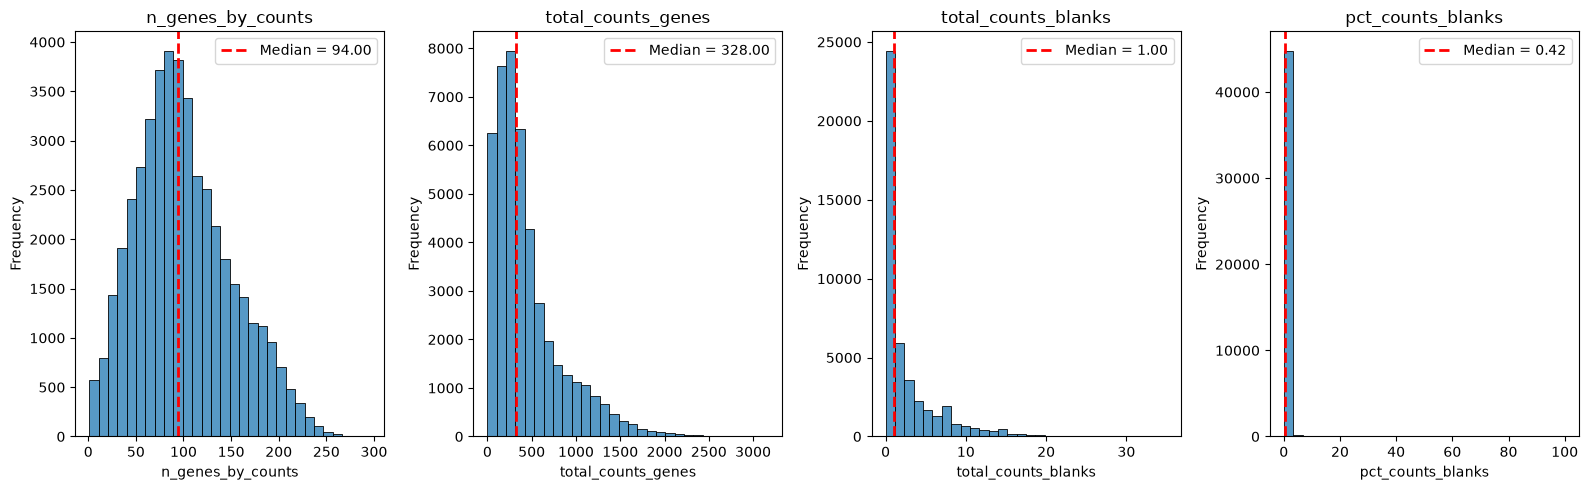

In [8]:
generate_qc_hist(adata=adata, parameters=[
    'n_genes_by_counts',
    'total_counts_genes',
    'total_counts_blanks',
    "pct_counts_blanks"
])

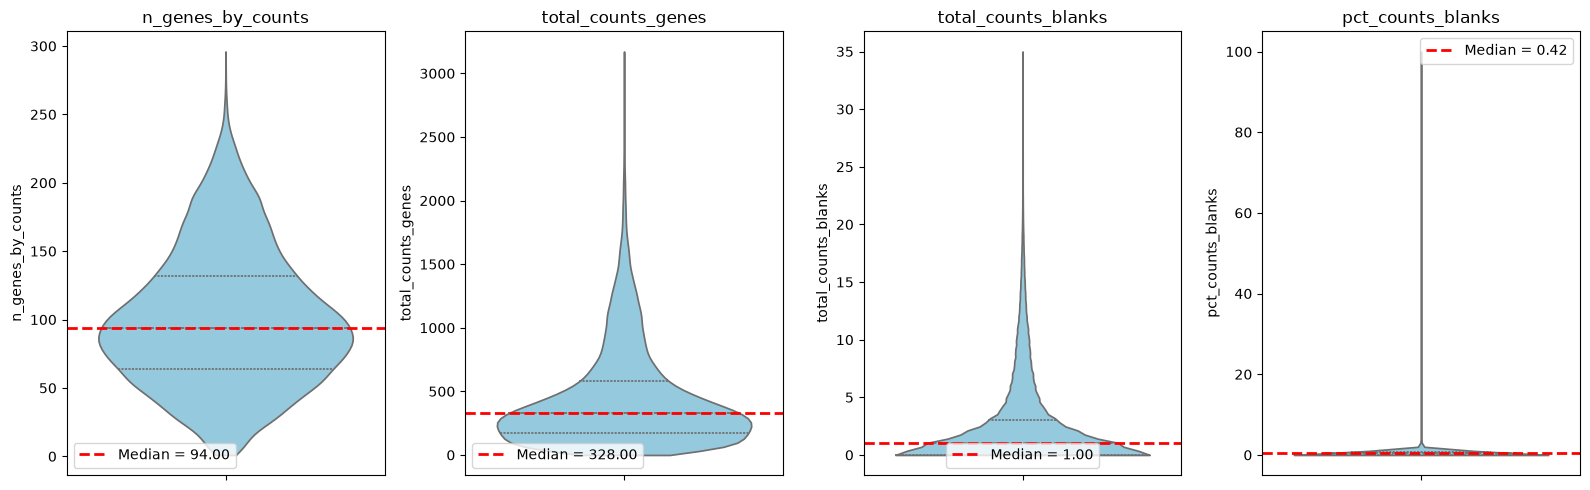

In [9]:
generate_qc_violin(adata=adata, parameters=[
    'n_genes_by_counts',
    'total_counts_genes',
    'total_counts_blanks',
    "pct_counts_blanks"
])

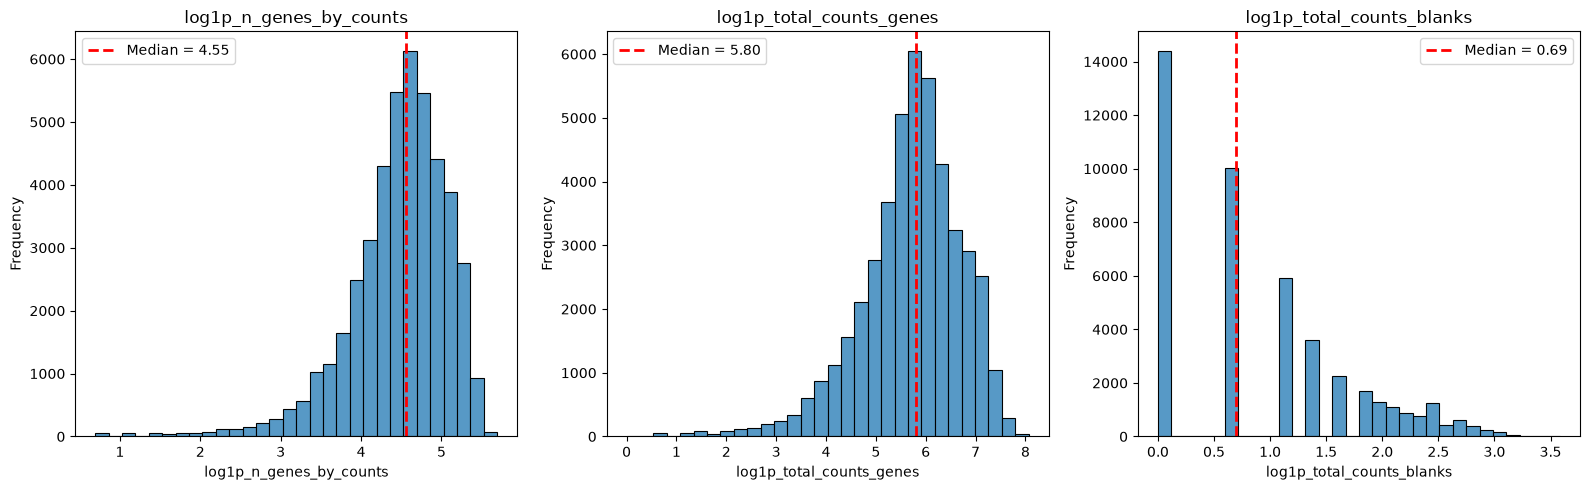

In [10]:
generate_qc_hist(adata=adata, parameters=[
    'log1p_n_genes_by_counts',
    'log1p_total_counts_genes',
    'log1p_total_counts_blanks',
    # "pct_counts_blanks"
])

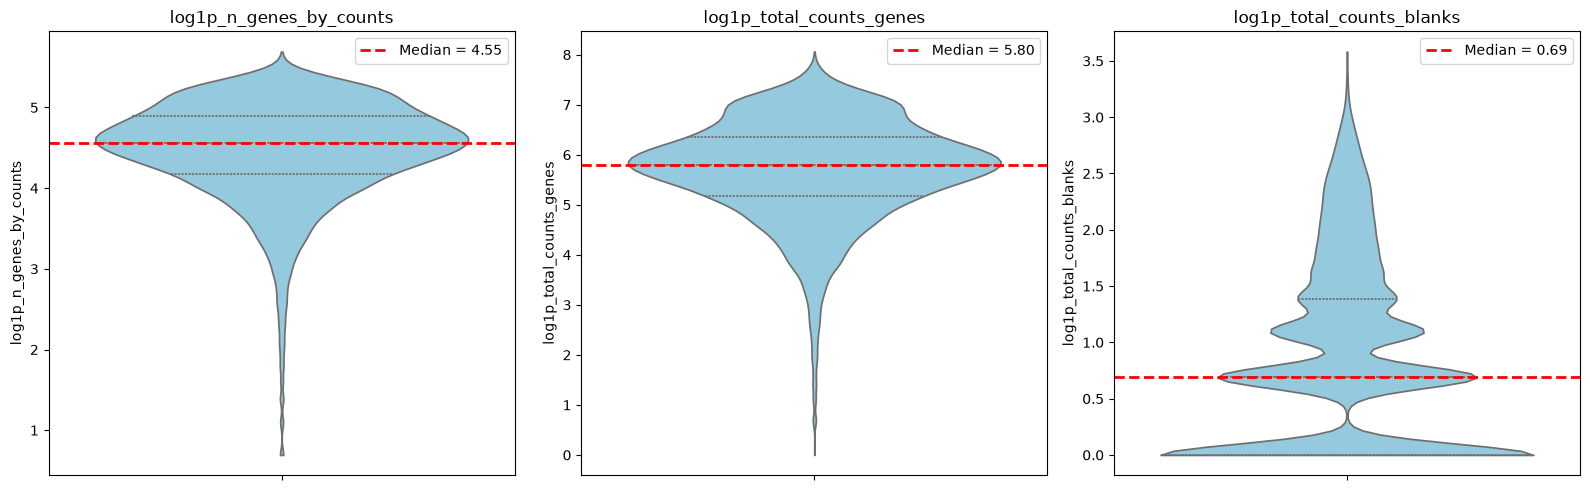

In [11]:
generate_qc_violin(adata=adata, parameters=[
    'log1p_n_genes_by_counts',
    'log1p_total_counts_genes',
    'log1p_total_counts_blanks',
    # "pct_counts_blanks"
])

In [12]:
adata.obs['pct_counts_blanks'].describe()

count    45139.000000
mean         0.544815
std          1.378891
min          0.000000
25%          0.000000
50%          0.417246
75%          0.767263
max        100.000000
Name: pct_counts_blanks, dtype: float64

In [13]:
blank_cutoff = adata.obs["pct_counts_blanks"].quantile(0.75)

adata.obs["high_blank_count"] = (
    adata.obs["pct_counts_blanks"] > blank_cutoff
)

condition = adata.obs["high_blank_count"]

print(f"75th percentile Blank percentage: {blank_cutoff} \n")

print("Counts:")
print(condition.value_counts())

print("\nPercentages:")
print((condition.value_counts(normalize=True) * 100).round(2))

75th percentile Blank percentage: 0.7672634271099744 

Counts:
high_blank_count
False    33860
True     11279
Name: count, dtype: int64

Percentages:
high_blank_count
False    75.01
True     24.99
Name: proportion, dtype: float64


## Define cells with high background noise

In [14]:
blank_cutoff = adata.obs["pct_counts_blanks"].quantile(0.95)

adata.obs["high_blank_count"] = (
    adata.obs["pct_counts_blanks"] > blank_cutoff
)

condition = adata.obs["high_blank_count"]

print(f"95th percentile Blank percentage: {blank_cutoff} \n")

print("Counts:")
print(condition.value_counts())

print("\nPercentages:")
print((condition.value_counts(normalize=True) * 100).round(2))

95th percentile Blank percentage: 1.4084507042253522 

Counts:
high_blank_count
False    42915
True      2224
Name: count, dtype: int64

Percentages:
high_blank_count
False    95.07
True      4.93
Name: proportion, dtype: float64


In [15]:
adata.obs["high_blank_count"] = (
    adata.obs["high_blank_count"]
    .astype(str)
    .replace({
        "True": "Above",
        "False": "Below",
        "1": "Above",
        "0": "Below"
    })
)

adata.obs["high_blank_count"] = pd.Categorical(
    adata.obs["high_blank_count"],
    categories=["Below", "Above"],
)

c:\Users\user\OneDrive\Desktop\GitHub\mini-spatial-series\env\Lib\site-packages\squidpy\pl\_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
c:\Users\user\OneDrive\Desktop\GitHub\mini-spatial-series\env\Lib\site-packages\squidpy\pl\_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
c:\Users\user\OneDrive\Desktop\GitHub\mini-spatial-series\env\Lib\site-packages\squidpy\pl\_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


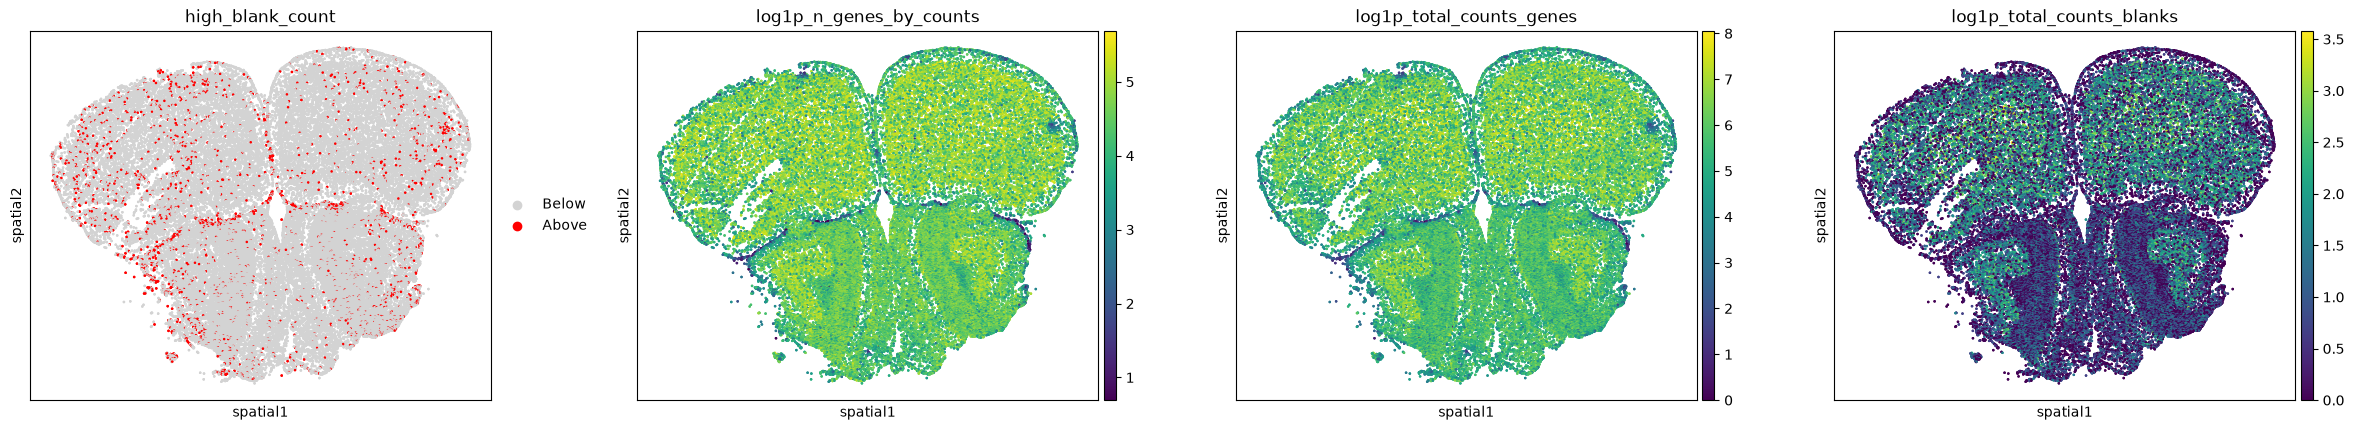

In [16]:
adata.uns.pop("high_blank_count_colors", None)
adata.uns["high_blank_count_colors"] = [
    "lightgray",  # Below
    "red",        # Above
    # "lightgray",  # NA
]

sq.pl.spatial_scatter(
    adata,
    shape=None,
    color=[
        "high_blank_count",
        'log1p_n_genes_by_counts',
        'log1p_total_counts_genes',
        'log1p_total_counts_blanks',
    ],
    # wspace=0.2,
)

In [17]:
sdata = adata[adata.obs['high_blank_count'] == "Above"].copy()
sdata

AnnData object with n_obs × n_vars = 2224 × 550
    obs: 'center_x', 'center_y', 'center_z', 'volume', 'area', 'polygon_center_x', 'polygon_center_y', 'polygon_center_z', 'SpotTable_cell_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_genes', 'log1p_total_counts_genes', 'pct_counts_genes', 'total_counts_blanks', 'log1p_total_counts_blanks', 'pct_counts_blanks', 'high_blank_count'
    var: 'probe_name', 'cells_with_reads', 'segmented_total_reads', 'unsegmented_total_reads', 'genes', 'blanks', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'SIS_repo_hash', 'cell_polygons', 'segmentation_metadata', 'high_blank_count_colors'
    obsm: 'spatial', 'spatial3d'
    layers: None (.X)

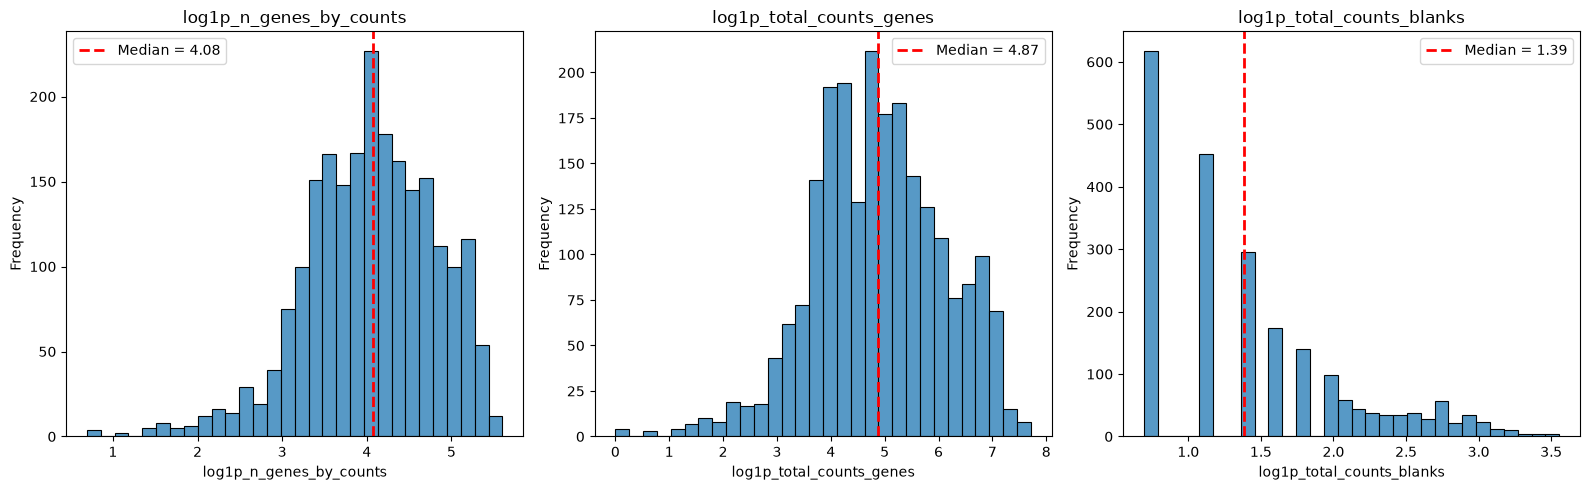

In [18]:
generate_qc_hist(adata=sdata, parameters=[
    'log1p_n_genes_by_counts',
    'log1p_total_counts_genes',
    'log1p_total_counts_blanks',
    # "pct_counts_blanks"
])

## Testing whether blank detections are unusually abundant

H0: Bi is consistent with the background model

H1: Bi exceeds the background model's expectation

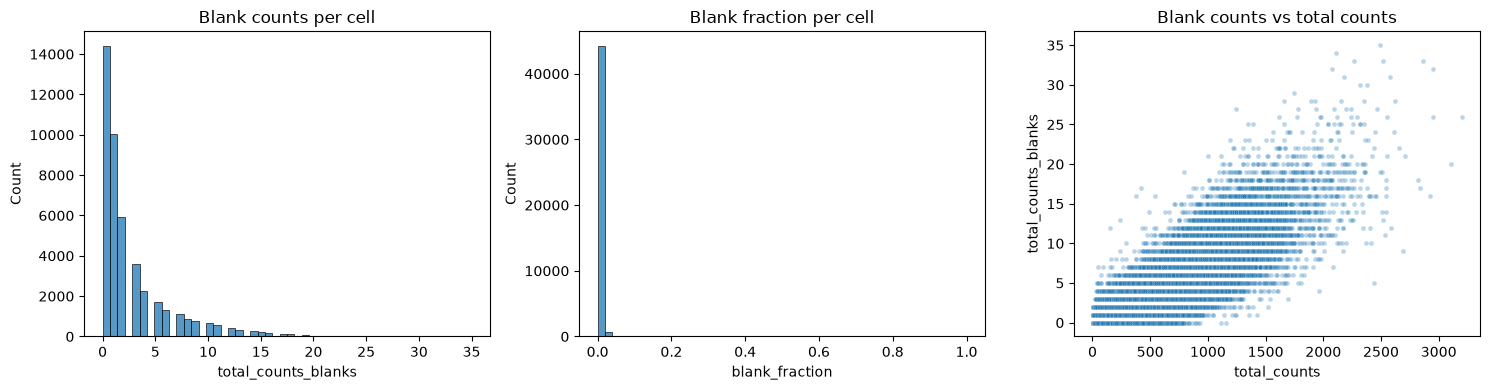

       total_counts  total_counts_blanks  blank_fraction
count  45139.000000         45139.000000    45139.000000
mean     447.013159             2.695363        0.005448
std      390.961755             3.745882        0.013789
min        1.000000             0.000000        0.000000
25%      177.000000             0.000000        0.000000
50%      330.000000             1.000000        0.004172
75%      581.000000             3.000000        0.007673
max     3198.000000            35.000000        1.000000


In [20]:
qc = adata.obs[
    ["total_counts", "total_counts_genes", "total_counts_blanks"]
].copy()

# Ensure numeric values and remove invalid observations for this analysis.
qc = qc.apply(pd.to_numeric, errors="coerce")
qc = qc.replace([np.inf, -np.inf], np.nan).dropna()

qc = qc.loc[
    (qc["total_counts"] > 0)
    & (qc["total_counts_blanks"] >= 0)
    & (qc["total_counts_genes"] >= 0)
].copy()

qc["blank_fraction"] = (
    qc["total_counts_blanks"] / qc["total_counts"]
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(
    data=qc, x="total_counts_blanks",
    bins=50, ax=axes[0]
)
axes[0].set_title("Blank counts per cell")

sns.histplot(
    data=qc, x="blank_fraction",
    bins=50, ax=axes[1]
)
axes[1].set_title("Blank fraction per cell")

sns.scatterplot(
    data=qc,
    x="total_counts",
    y="total_counts_blanks",
    alpha=0.3,
    s=12,
    ax=axes[2],
)
axes[2].set_title("Blank counts vs total counts")

plt.tight_layout()
plt.show()

print(qc[[
    "total_counts",
    "total_counts_blanks",
    "blank_fraction",
]].describe())


In [23]:

import statsmodels.api as sm
import statsmodels.formula.api as smf

# Use a DataFrame with the observation-level measurements.
model_data = qc.copy()

model_data["log_total_counts"] = np.log(
    model_data["total_counts"]
)

# Fit a negative binomial regression with an exposure offset.
model = smf.glm(
    formula="total_counts_blanks ~ 1",
    data=model_data,
    family=sm.families.NegativeBinomial(),
    offset=model_data["log_total_counts"],
).fit()

print(model.summary())


                  Generalized Linear Model Regression Results                  
Dep. Variable:     total_counts_blanks   No. Observations:                45139
Model:                             GLM   Df Residuals:                    45138
Model Family:         NegativeBinomial   Df Model:                            0
Link Function:                     Log   Scale:                          1.0000
Method:                           IRLS   Log-Likelihood:                -81196.
Date:                 Tue, 27 Oct 2026   Deviance:                       27918.
Time:                         12:56:32   Pearson chi2:                 2.60e+04
No. Iterations:                      6   Pseudo R-squ. (CS):          6.661e-16
Covariance Type:             nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.2364      0.006   -863.30

C:\Users\user\AppData\Local\Temp\ipykernel_8664\827627230.py:15: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial(),


In [24]:
print("Zero blank counts:", (qc["total_counts_blanks"] == 0).sum())
print(
    "Zero gene counts:",
    (qc["total_counts_genes"] == 0).sum()
)

print("Observed mean blank count:",
      qc["total_counts_blanks"].mean())

print("Observed variance blank count:",
      qc["total_counts_blanks"].var())

print("Observed blank fraction:",
      qc["total_counts_blanks"].sum() / qc["total_counts"].sum())

Zero blank counts: 14409
Zero gene counts: 4
Observed mean blank count: 2.6953632114136337
Observed variance blank count: 14.031634975412043
Observed blank fraction: 0.006029717817076225


In [27]:
model_data = qc.loc[
    qc["total_counts_genes"] > 0
].copy()

y = model_data["total_counts_blanks"].astype(int)

X = np.ones((len(model_data), 1))
offset = np.log(model_data["total_counts_genes"])

nb_model = sm.NegativeBinomial(
    y,
    X,
    loglike_method="nb2",
    offset=offset,
)

nb_result = nb_model.fit(disp=False)

print(nb_result.params)
print("Estimated dispersion (alpha):", nb_result.params.iloc[-1])


const   -5.167241
alpha    0.165435
dtype: float64
Estimated dispersion (alpha): 0.1654346432172149


 blank_count  observed_fraction  expected_fraction
           0           0.319242           0.265416
           1           0.222399           0.218845
           2           0.131428           0.156674
           3           0.079805           0.107115
           4           0.050161           0.072724
           5           0.037465           0.049970
           6           0.028714           0.034996
           7           0.024283           0.024975
           8           0.019231           0.018095
           9           0.017171           0.013252
          10           0.015066           0.009771
          11           0.012540           0.007233
          12           0.009217           0.005365
          13           0.007444           0.003984
          14           0.006115           0.002959
          15           0.004941           0.002199
          16           0.003722           0.001634
          17           0.003190           0.001215
          18           0.002238

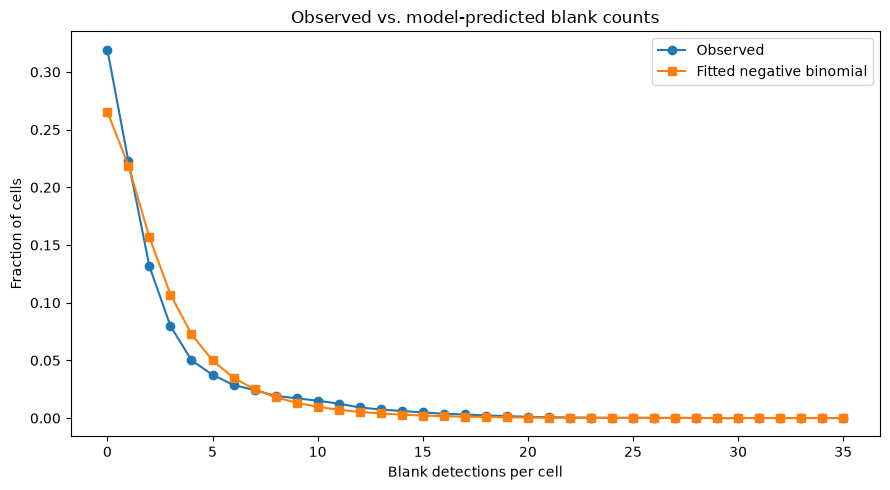

In [29]:
from scipy.stats import nbinom

# Reconstruct the data used to fit the model
observed = y.to_numpy()
mu = nb_result.predict()

alpha = float(nb_result.params["alpha"])

# NB2 parameterization:
# variance = mu + alpha * mu**2
size = 1 / alpha
prob = size / (size + mu)

max_count = int(observed.max())
counts = np.arange(max_count + 1)

observed_freq = np.bincount(
    observed, minlength=max_count + 1
) / len(observed)

expected_freq = np.array([
    nbinom.pmf(k, size, prob).mean()
    for k in counts
])

comparison = pd.DataFrame({
    "blank_count": counts,
    "observed_fraction": observed_freq,
    "expected_fraction": expected_freq,
})

print(comparison.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.plot(
    counts, observed_freq,
    marker="o", label="Observed"
)
plt.plot(
    counts, expected_freq,
    marker="s", label="Fitted negative binomial"
)
plt.xlabel("Blank detections per cell")
plt.ylabel("Fraction of cells")
plt.title("Observed vs. model-predicted blank counts")
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
from statsmodels.stats.multitest import multipletests

# Use the same cells used to fit the negative binomial model
results = model_data.copy()

# Observed blank counts and fitted expected counts
observed = results["total_counts_blanks"].to_numpy(dtype=int)
mu = np.asarray(nb_result.predict())

# Estimated NB2 dispersion
alpha = float(nb_result.params["alpha"])

# NB2 parameterization:
# variance = mu + alpha * mu**2
size = 1.0 / alpha
prob = size / (size + mu)

# Upper-tail probability P(Y >= observed)
# sf(k - 1) = P(Y >= k), including the observed count
p_values = nbinom.sf(observed - 1, size, prob)

# Benjamini-Hochberg multiple-testing correction
reject, q_values, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="fdr_bh"
)

results["expected_blanks"] = mu
results["blank_count_pvalue"] = p_values
results["blank_count_qvalue"] = q_values
results["excess_blank_flag_exploratory"] = reject

print(f"Cells tested: {len(results):,}")
print(f"Exploratory flags (BH q < 0.05): {reject.sum():,}")
print(f"Percentage flagged: {100 * reject.mean():.2f}%")
print(f"Minimum p-value: {p_values.min():.3e}")
print(f"Minimum q-value: {q_values.min():.3e}")

Cells tested: 45,135
Exploratory flags (BH q < 0.05): 6
Percentage flagged: 0.01%
Minimum p-value: 2.876e-08
Minimum q-value: 1.298e-03


In [31]:
top_cells = results.sort_values(
    ["blank_count_qvalue", "blank_count_pvalue"]
).head(20)

columns_to_show = [
    "total_counts_genes",
    "total_counts_blanks",
    "expected_blanks",
    "blank_count_pvalue",
    "blank_count_qvalue",
    "excess_blank_flag_exploratory",
]

print(top_cells[columns_to_show].to_string())

                     total_counts_genes  total_counts_blanks  expected_blanks  blank_count_pvalue  blank_count_qvalue  excess_blank_flag_exploratory
1296400350_CP_13979                 143                   12         0.815139        2.876240e-08            0.001298                           True
1296400350_CP_13982                  45                    7         0.256512        1.267718e-07            0.002861                           True
1296400350_CP_13970                 229                   13         1.305363        6.384707e-07            0.009606                           True
1296400350_CP_13965                 399                   17         2.274409        1.661797e-06            0.016654                           True
1296400350_CP_2631                  365                   16         2.080600        1.844879e-06            0.016654                           True
1296400350_CP_16788                  82                    7         0.467422        5.817262e-06         

In [32]:
flagged_ids = results.index[
    results["excess_blank_flag_exploratory"]
]

adata.obs["excess_blank_flag_exploratory"] = (
    adata.obs_names.isin(flagged_ids)
)

print(
    adata.obs["excess_blank_flag_exploratory"]
    .value_counts()
)

# Check which spatial coordinate systems are available
print(adata.obsm.keys())

excess_blank_flag_exploratory
False    45133
True         6
Name: count, dtype: int64
KeysView(AxisArrays with keys: 'spatial', 'spatial3d')


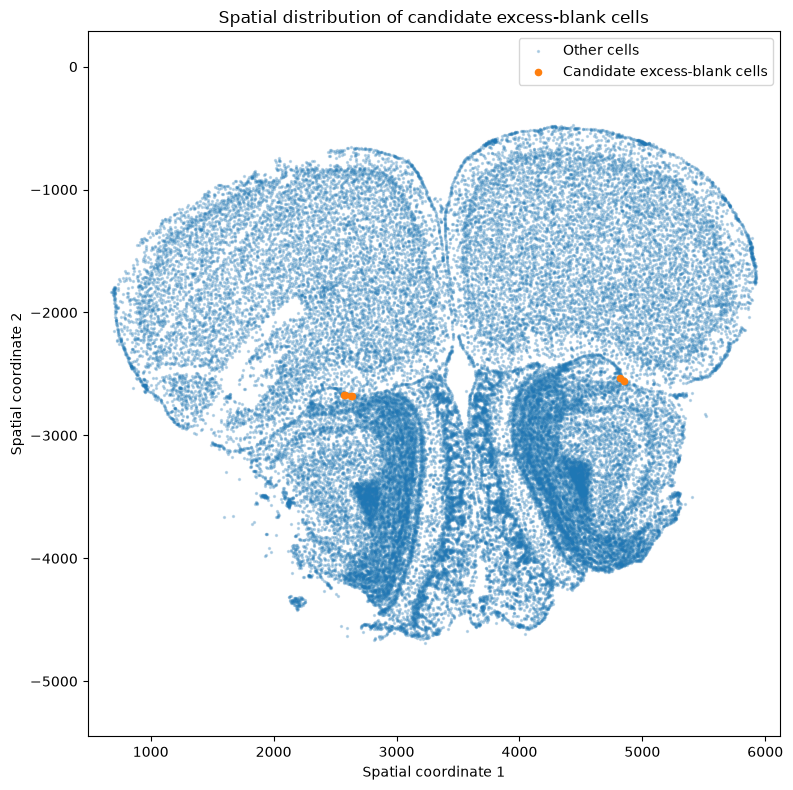

In [37]:
coords = adata.obsm["spatial"]

flag = adata.obs[
    "excess_blank_flag_exploratory"
].to_numpy()

plt.figure(figsize=(8, 8))

plt.scatter(
    coords[~flag, 0],
    -coords[~flag, 1],
    s=2,
    alpha=0.25,
    label="Other cells",
)

plt.scatter(
    coords[flag, 0],
    -coords[flag, 1],
    s=20,
    label="Candidate excess-blank cells",
)

plt.xlabel("Spatial coordinate 1")
plt.ylabel("Spatial coordinate 2")
plt.title("Spatial distribution of candidate excess-blank cells")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.show()

## Conclusion